# Room 2: reflectivity production

Generate `reflectivity.h5` from `room_2_reflectivity.json`, then display and save `reflectivity.png` beside this notebook. The map shows assigned material reflectivity at the first ray hit, averaged over valid samples; it is not inferred from photon counts.

Use the project Python environment as the kernel. For native generation, launch Jupyter from the repository root after activating the runtime:

```bash
source ./activate.sh --full
jupyter lab examples/example_room_2/reflectivity.ipynb
```

Plotting existing HDF5 data does not require the native runtime. Running the plotting cell overwrites `reflectivity.png`.


In [1]:
from pathlib import Path
import json
import subprocess
import sys
import h5py
import numpy as np
import matplotlib.pyplot as plt

root = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "src/synthetic_data_generation").is_dir()
             and (p / "examples/example_room_2/room_2_reflectivity.json").is_file()), None)
if root is None:
    raise RuntimeError("Open this notebook from within the repository.")
sys.path.insert(0, str(root / "src"))
from spad_noise_injection.diffuse_map import read_diffuse_from_h5

output_dir = root / "examples/example_room_2"
config_path = output_dir / "room_2_reflectivity.json"
h5_path = output_dir / "reflectivity.h5"
config = json.loads(config_path.read_text())
options = next(stage["options"] for stage in config["stages"]
               if stage["command"] == "diffuse-map")
print(json.dumps(config, indent=2))


{
  "output_dir": ".",
  "stages": [
    {
      "command": "diffuse-map",
      "options": {
        "scene": "room_2.usda",
        "output": "{output_dir}/reflectivity.h5",
        "camera_position": [
          3.5887303168332956,
          96.95825285901212,
          67.4154305598385
        ],
        "look_at": [
          3.5887303168332956,
          -103.04174714098788,
          70.0
        ],
        "up": [
          0.0,
          0.0,
          1.0
        ],
        "baseline_offset": [
          5,
          0,
          0
        ],
        "detector_width": 8,
        "detector_height": 8,
        "fov_x": 90,
        "fov_y": 90,
        "width": 60,
        "height": 60,
        "samples_per_ray": 3200,
        "seed": 4
      }
    }
  ]
}


## Generate or reuse the map

Existing data is reused by default. Set `regenerate = True` after changing scene materials, geometry, or camera settings. Generation requires the built native tracer and activated runtime; shape checks cannot detect stale material settings.

In [2]:
regenerate = False
if regenerate or not h5_path.is_file():
    subprocess.run(
        [sys.executable, "-m", "synthetic_data_generation", "run",
         "--config", str(config_path)],
        cwd=root, check=True,
    )
print(f"Using {h5_path}")


Using /home/peizhao/synthetic_data_generation/examples/example_room_2/reflectivity.h5


## Load and validate

Read reflectivity with the shared `read_diffuse_from_h5()` function. Check the configured grid and valid samples before plotting.

In [3]:
reflectivity = read_diffuse_from_h5(str(h5_path))
with h5py.File(h5_path, "r") as handle:
    valid_count = handle["diffuse_data"]["valid_count"]
expected_shape = (options["width"], options["height"])
assert reflectivity.shape == expected_shape, (reflectivity.shape, expected_shape)
assert valid_count.shape == expected_shape
valid = valid_count > 0
assert valid.any(), "No valid ray hits in the reflectivity map."
assert np.isfinite(reflectivity[valid]).all()
assert ((reflectivity[valid] >= 0) & (reflectivity[valid] <= 1)).all()
print(f"Map shape: {reflectivity.shape}; valid pixels: {valid.sum()}/{valid.size}")


Map shape: (60, 60); valid pixels: 3600/3600


## Display and save reflectivity

Use a fixed 0–1 reflectivity scale. Pixels without valid ray hits are shown in black. The plot transposes the map and uses a lower origin to match the other example images.

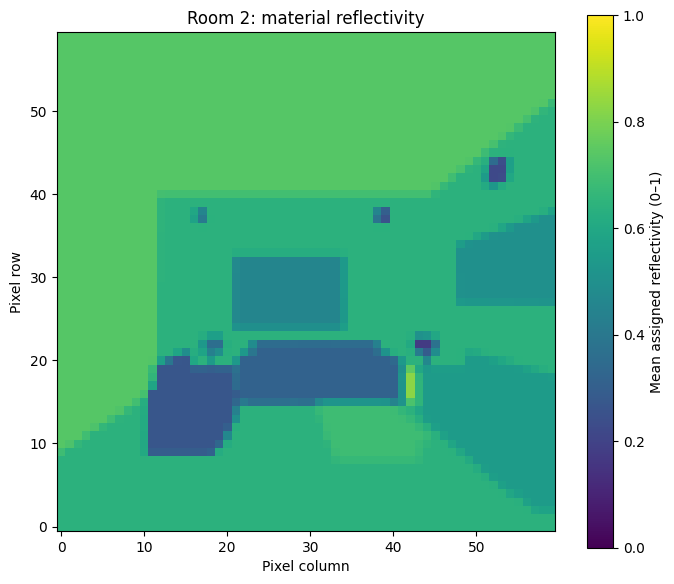

/home/peizhao/synthetic_data_generation/examples/example_room_2/reflectivity.png


In [4]:
masked_reflectivity = np.ma.masked_where(~valid, reflectivity)
cmap = plt.get_cmap("viridis").copy()
cmap.set_bad("black")
fig, ax = plt.subplots(figsize=(7, 6))
image = ax.imshow(
    masked_reflectivity.T, origin="lower", interpolation="nearest",
    cmap=cmap, vmin=0, vmax=1,
)
fig.colorbar(image, ax=ax, label="Mean assigned reflectivity (0–1)")
ax.set(title="Room 2: material reflectivity", xlabel="Pixel column", ylabel="Pixel row")
fig.tight_layout()
png_path = output_dir / "reflectivity.png"
fig.savefig(png_path, dpi=180)
plt.show()
plt.close(fig)
print(png_path)
